# Movie Success Analysis

## What makes a film successful? A data mining & visualization study

**Author:** Wenhao Li

This project analyzes a **movie metadata dataset** (~4,800 films) through a complete data mining pipeline to understand what drives a movie's critical and commercial success.

The workflow covers:

- **Data cleaning & feature engineering** - handling missing and pseudo-missing values, transforming release dates, genres and keywords
- **Exploratory data analysis (EDA)** - 25+ visualizations of ratings, budgets, trends and relationships
- **Modelling** - KMeans clustering to segment movies, and a classifier to predict high-rated films
- **Insights** - keyword and genre patterns that separate high-rated from low-rated movies

*Tools: Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, WordCloud*

## Step 1: Data Import and Initial Inspection


**Required Packages**

This notebook uses the following Python libraries:

- pandas
- numpy
- matplotlib
- seaborn
- wordcloud
- scikit-learn (sklearn)

If needed, install via pip:

```bash
pip install pandas numpy matplotlib seaborn wordcloud scikit-learn

### 1.1 Importing Libraries




In [1]:

# Step 1.1: Import essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore a benign joblib/loky warning (CPU-core detection) that can appear on Windows
import warnings
warnings.filterwarnings('ignore', message='Could not find the number of physical cores')

# Set seaborn style
sns.set(style="whitegrid")




To begin the analysis, I imported the essential Python libraries:

- `pandas` for data manipulation,
- `numpy` for numerical computations,
- `matplotlib` and `seaborn` for data visualisation.

These libraries form the foundation of the data analysis workflow.

### 1.2 Loading the Dataset



In [2]:
# Step 1.2: Load the dataset
df = pd.read_csv("movies.csv")

# Preview the first 5 rows
df.head()


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


The dataset `movies.csv` was loaded into a pandas DataFrame named `df`. I used the `.head()` function to preview the first five rows and understand the structure of the data. Each row appears to represent a single movie, with attributes such as title, year, genre, rating, votes, and more.


### 1.3 Initial Data Inspection and Quality Check



In [3]:
# Step 1.3: Basic structure and summary
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

### 1.4: Count missing values


In [4]:
# Step 1.4: Count missing values
df.isnull().sum()


budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64

### 1.5: Summary statistics (numeric + categorical)

In [5]:
# Step 1.5: Summary statistics (numeric + categorical)
df.describe(include='all')


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
count,4.803000e+03,4803,1712,4803.000000,4803,4803,4803,4800,4803.000000,4803,4803,4802,4.803000e+03,4801.000000,4803,4803,3959,4803,4803.000000,4803.000000
unique,NaN,1175,1691,NaN,4222,37,4801,4800,NaN,3697,469,3280,NaN,NaN,544,3,3944,4800,NaN,NaN
top,NaN,"[{""id"": 18, ""name"": ""Drama""}]",http://www.thehungergames.movie/,NaN,[],en,Batman,"'Breaking Upwards' explores a young, real-life...",NaN,[],"[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2006-01-01,NaN,NaN,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Based on a true story.,The Host,NaN,NaN
freq,NaN,370,4,NaN,412,4505,2,1,NaN,351,2977,10,NaN,NaN,3171,4795,3,2,NaN,NaN
mean,2.904504e+07,NaN,NaN,57165.484281,NaN,NaN,NaN,NaN,21.492301,NaN,NaN,NaN,8.226064e+07,106.875859,NaN,NaN,NaN,NaN,6.092172,690.217989
std,4.072239e+07,NaN,NaN,88694.614033,NaN,NaN,NaN,NaN,31.816650,NaN,NaN,NaN,1.628571e+08,22.611935,NaN,NaN,NaN,NaN,1.194612,1234.585891
min,0.000000e+00,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.000000e+00,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000
25%,7.900000e+05,NaN,NaN,9014.500000,NaN,NaN,NaN,NaN,4.668070,NaN,NaN,NaN,0.000000e+00,94.000000,NaN,NaN,NaN,NaN,5.600000,54.000000
50%,1.500000e+07,NaN,NaN,14629.000000,NaN,NaN,NaN,NaN,12.921594,NaN,NaN,NaN,1.917000e+07,103.000000,NaN,NaN,NaN,NaN,6.200000,235.000000
75%,4.000000e+07,NaN,NaN,58610.500000,NaN,NaN,NaN,NaN,28.313505,NaN,NaN,NaN,9.291719e+07,118.000000,NaN,NaN,NaN,NaN,6.800000,737.000000


### 1.6: Check dataset size

In [6]:
# Step 1.6: Check dataset size
print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns.")


Dataset has 4803 rows and 20 columns.


To prepare for deeper analysis, I performed several basic checks:

- `df.info()` reveals the data types of each column and shows which columns have missing values.
- `df.isnull().sum()` counts the missing values for each column.
- `df.describe(include='all')` provides descriptive statistics for both numeric and categorical columns.
- I also printed the dataset shape to confirm the number of rows and columns.

### Key Observations:
- Some fields such as budget, revenue, or overview contain missing or incomplete values.
- Certain columns may require transformation (e.g. `year` to datetime or categorical bins).
- There may be opportunities to clean, combine, or derive new features based on this initial inspection.

In the next step, I will clean and preprocess the dataset to prepare it for analysis.


## Step 2: Data Cleaning and Feature Engineering



### 2.1 Removing Duplicate Rows



In [7]:
# Step 2.1: Check and drop duplicates
print("Duplicate rows before:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Duplicate rows after:", df.duplicated().sum())


Duplicate rows before: 0
Duplicate rows after: 0


Duplicate records can distort analysis, especially in aggregations or frequency counts. I used `.duplicated()` to detect duplicates and `.drop_duplicates()` to remove them. This ensures that each movie entry is unique.


### 2.2 Visualising Missing Values



<Axes: >

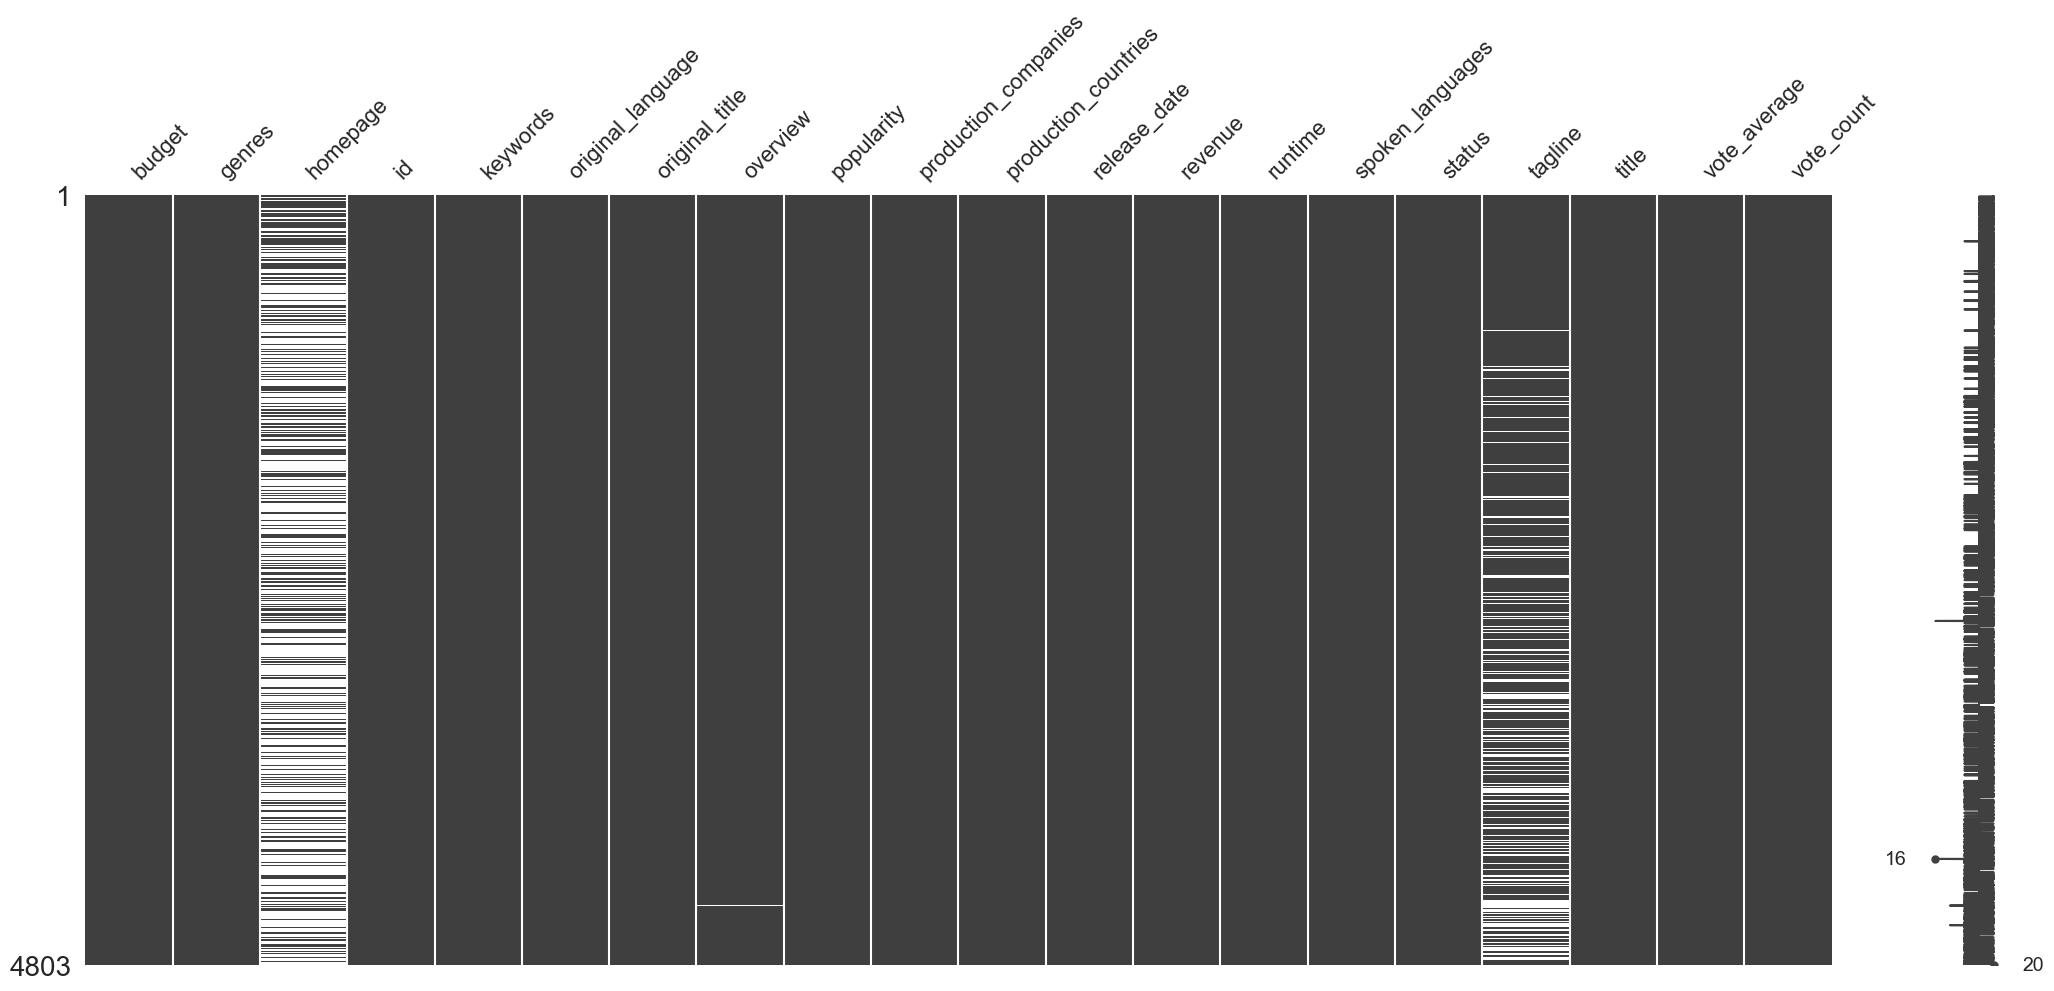

In [8]:
# Step 2.2: Visualise missing values
import missingno as msno
msno.matrix(df)


Using the `missingno` package, I visualised missing values in the dataset. This helps in understanding which columns have frequent or systematic gaps, which guides how to handle them.


### 2.3 Handling Missing Values


In [9]:
# Step 2.3: Handle missing values (based on actual column names)

# Drop rows where 'vote_average' or 'vote_count' is missing (critical for analysis)
df.dropna(subset=['vote_average', 'vote_count'], inplace=True)

# Fill missing 'budget', 'revenue', and 'runtime' with median
for col in ['budget', 'revenue', 'runtime']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())




After inspecting the actual columns in the dataset, I adjusted the missing value treatment accordingly:

- I removed rows where `vote_average` (rating) or `vote_count` is missing, since these are essential for evaluating a movie's popularity and quality.
- For numeric columns like `budget`, `revenue`, and `runtime`, I filled missing values using the median to avoid distortion from extreme values.


### 2.4 Handling Pseudo-Missing Values



In [10]:
# Treat 0 values in budget, revenue, vote_count as missing
for col in ['budget', 'revenue', 'vote_count','vote_average', 'runtime']:
    df[col] = df[col].replace(0, np.nan)

In [11]:
# Replace "[]" strings with np.nan in object columns
list_like_cols = ['genres', 'keywords', 'production_companies', 'production_countries', 'spoken_languages']
for col in list_like_cols:
    df[col] = df[col].replace('[]', np.nan)

In [12]:
df_clean = df.copy()

for col in ['budget', 'revenue', 'vote_count', 'vote_average']:
    df_clean[col] = df_clean[col].replace(0, np.nan)

df_clean.dropna(subset=['budget', 'vote_average'], inplace=True)


<Axes: >

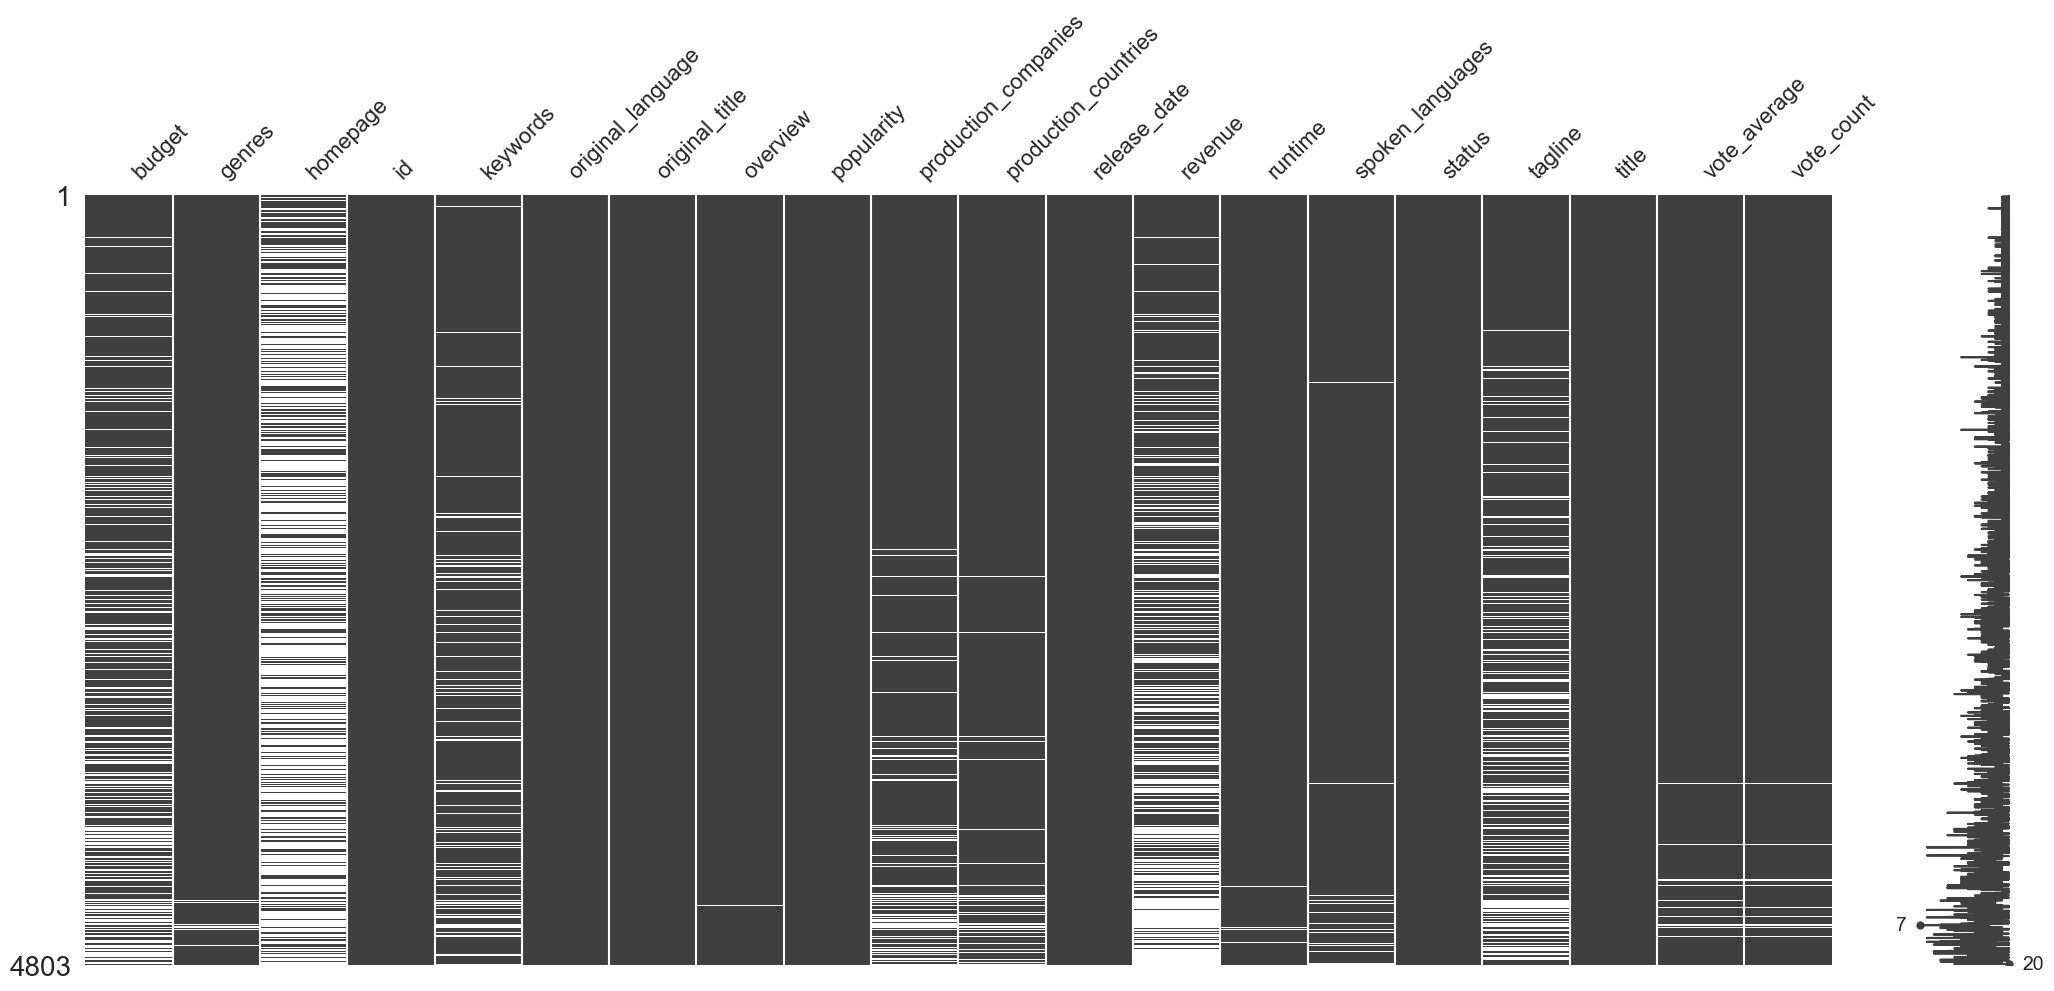

In [13]:
import missingno as msno
msno.matrix(df)

In [14]:
df.dropna(subset=['vote_average', 'vote_count'], inplace=True)

In [15]:
# After replacement, fill budget/revenue with median again
#for col in ['budget', 'revenue', 'vote_count']:
#    if df[col].isnull().sum() > 0:
#        df[col].fillna(df[col].median(), inplace=True)

Upon further inspection, I found that some fields, although non-null, contained zero values (e.g., `budget`, `revenue`, `vote_count`) or empty list strings such as `'[]'` (in `genres`, `keywords`, etc.). These are pseudo-missing values that can distort analysis.

- Zero values in numerical fields were replaced with `NaN` .
- Text fields containing `'[]'` were considered missing and replaced with `NaN`.

This ensures the dataset reflects actual missingness more accurately and prevents skewed results in clustering or classification.


After replacing zero values with `NaN`, I won't replace it with median right here. Why?

**There are too many missing values, If I replace them with median it will affect my later study.**

### 2.5 Feature Transformation



In [16]:
# Step 2.4: Convert 'release_date' to datetime format
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

# Extract year from release_date
df['release_year'] = df['release_date'].dt.year

# Create decade column
df['decade'] = (df['release_year'] // 10) * 10

# Create binary high-rating labels at two thresholds (>= 8.0 strict, >= 7.0 inclusive)
df['is_high_rating1'] = df['vote_average'] >= 8.0
df['is_high_rating2'] = df['vote_average'] >= 7.0


Since the dataset includes a `release_date` field, I converted it to datetime format using `pd.to_datetime()`.

I then extracted the year component to create a new column `release_year`, and derived a `decade` column to allow for temporal trend analysis (e.g., comparing movie ratings across decades).

Additionally, I created a binary column `is_high_rating` to indicate whether a movie has a rating of 7.0 or higher. This will be useful in classification and visualisation tasks later.


In [17]:
# Show new columns
df[['release_date', 'release_year', 'decade', 'vote_average', 'is_high_rating1', 'is_high_rating2']].head()


,release_date,release_year,decade,vote_average,is_high_rating1,is_high_rating2
0,2009-12-10,2009,2000,7.2,False,True
1,2007-05-19,2007,2000,6.9,False,False
2,2015-10-26,2015,2010,6.3,False,False
3,2012-07-16,2012,2010,7.6,False,True
4,2012-03-07,2012,2010,6.1,False,False


### 2.6 Step 2 Summary

In [18]:
# Step 2.5: Confirm cleaning
df.info()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
Index: 4740 entries, 0 to 4802
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   budget                3755 non-null   float64       
 1   genres                4727 non-null   object        
 2   homepage              1699 non-null   object        
 3   id                    4740 non-null   int64         
 4   keywords              4370 non-null   object        
 5   original_language     4740 non-null   object        
 6   original_title        4740 non-null   object        
 7   overview              4738 non-null   object        
 8   popularity            4740 non-null   float64       
 9   production_companies  4428 non-null   object        
 10  production_countries  4594 non-null   object        
 11  release_date          4740 non-null   datetime64[ns]
 12  revenue               3374 non-null   float64       
 13  runtime               4

budget                   985
genres                    13
homepage                3041
id                         0
keywords                 370
original_language          0
original_title             0
overview                   2
popularity                 0
production_companies     312
production_countries     146
release_date               0
revenue                 1366
runtime                   23
spoken_languages          64
status                     0
tagline                  796
title                      0
vote_average               0
vote_count                 0
release_year               0
decade                     0
is_high_rating1            0
is_high_rating2            0
dtype: int64

The dataset has been successfully cleaned and prepared:

- All duplicate rows were removed.
- Missing values in critical fields (`vote_average`, `vote_count`, `budget`, `revenue`, `runtime`) were handled appropriately.
- Non-critical missing values in `homepage`, `tagline`, and `overview` were retained, as they are not required for the main analysis.
- A new column `release_year` was extracted from `release_date`.
- A `decade` column was generated for temporal analysis.
- A binary column `is_high_rating` was created to indicate whether a movie's rating is 7.0 or higher.

The cleaned dataset is now ready for exploratory data analysis (EDA).


## Step 3: Exploratory Data Analysis (EDA)


### 3.1 Distribution of Movie Ratings

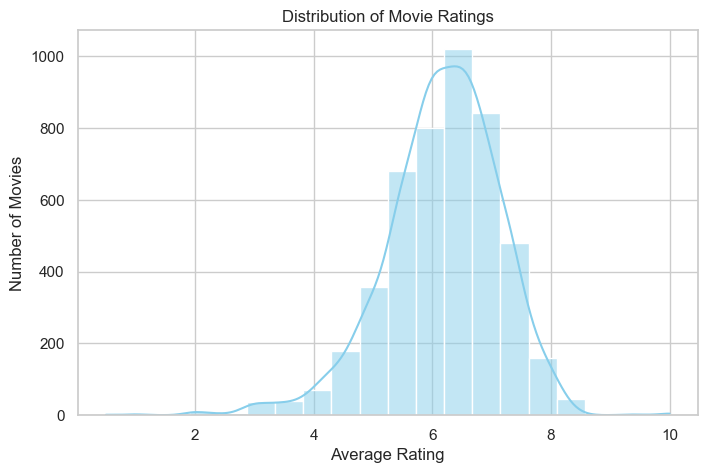

In [19]:
# Step 3.1: Distribution of movie ratings (vote_average)
plt.figure(figsize=(8, 5))
sns.histplot(df['vote_average'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Movie Ratings')
plt.xlabel('Average Rating')
plt.ylabel('Number of Movies')
plt.show()


This histogram shows the distribution of `vote_average`, which represents the average user rating for each movie.

- Most movies have ratings between 5 and 7.
- There are fewer movies with very high (above 8) or very low (below 4) ratings.
- The distribution is slightly right-skewed, indicating fewer highly-rated movies.

This insight helps define thresholds (e.g., what counts as a "high rating") and informs later classification or clustering.


### 3.2 Distribution of Movie Budgets

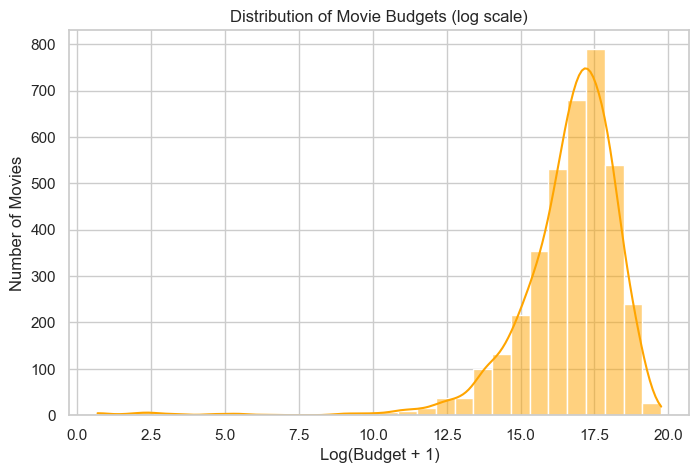

In [20]:
# Step 3.2: Distribution of movie budget (log scale to reduce skew)
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df['budget']), bins=30, kde=True, color='orange')
plt.title('Distribution of Movie Budgets (log scale)')
plt.xlabel('Log(Budget + 1)')
plt.ylabel('Number of Movies')
plt.show()


The original `budget` values are highly skewed due to outliers (some movies have extremely large budgets).  
To better visualise the distribution, I used a logarithmic scale with `log1p()` transformation.

- Most movies have relatively low budgets.
- A small number of movies have very large budgets, possibly blockbusters.

This variable will be explored in relation to ratings and revenue in later sections.

### 3.3 Number of Movies Released by Year

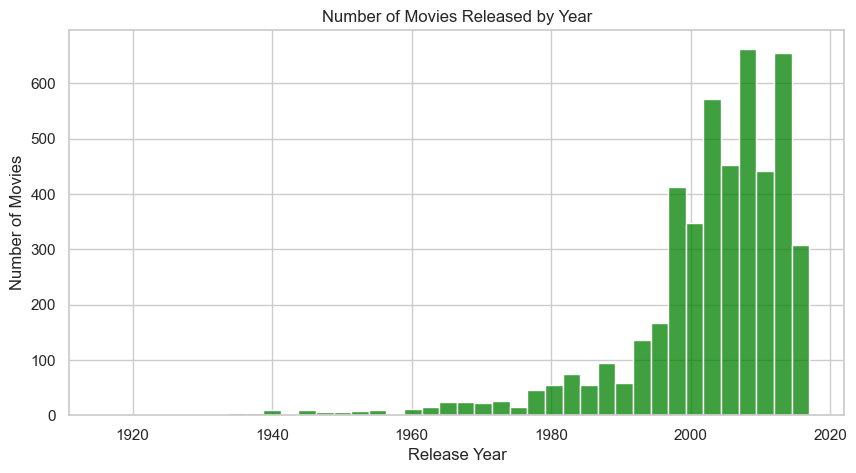

In [21]:
# Step 3.3: Movie release trend over time
plt.figure(figsize=(10, 5))
sns.histplot(df['release_year'].dropna(), bins=40, kde=False, color='green')
plt.title('Number of Movies Released by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')
plt.show()


This plot shows the count of movies released each year.

- There has been a general increase in the number of movies produced over time.
- A notable rise can be observed from the 1990s to 2010s.
- Slight drops may correspond to data coverage or industry changes.

Understanding the temporal trend provides context for how ratings or budgets may change over time.


#### 3.4.1 Relationship Between Budget and Rating


We aim to explore whether there is a relationship between a movie’s **budget** and its **average rating**. In other words:  
> “Do movies with bigger budgets tend to receive higher ratings?”

We use two approaches for scatter plot visualization:

1. The relationship between **original budget (linear scale)** and rating  
2. The relationship after applying a **log transformation** to the budget (`log(budget + 1)`)

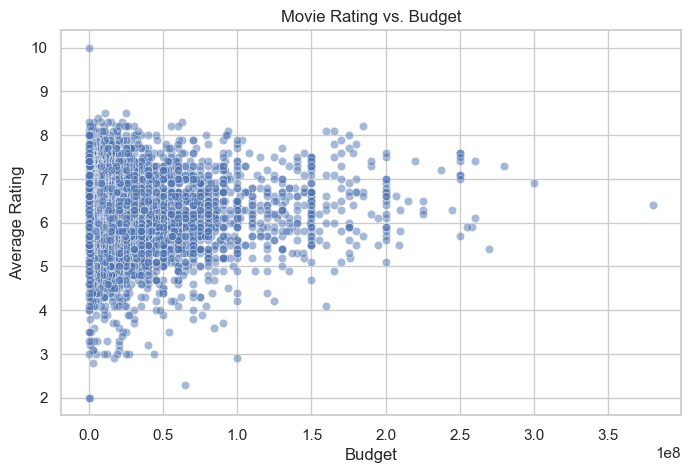

In [22]:
# Step 3.4.1: Scatter plot of rating vs budget
df_plot1 = df[(df['budget'] > 0) & (df['vote_average'] > 1)]
plt.figure(figsize=(8, 5))
sns.scatterplot(x='budget', y='vote_average', data=df_plot1, alpha=0.5)
plt.title('Movie Rating vs. Budget')
plt.xlabel('Budget')
plt.ylabel('Average Rating')
plt.show()


Problems with raw budget values:
- Most data points are **clustered on the left**, making it hard to observe details
- A few extremely high-budget movies **stretch the plot**, reducing clarity

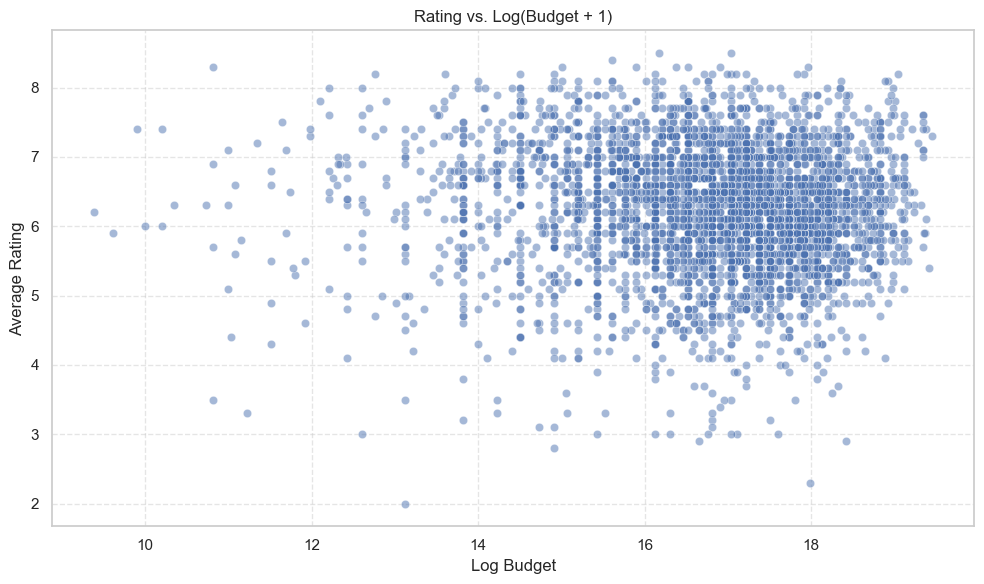

In [23]:
# Optional: log-transformed scatter plot
df_plot2 = df[(df['budget'] > 1e4) & (df['budget'] < 3e8) & (df['vote_average'] > 1)].copy()
df_plot2['log_budget'] = np.log1p(df_plot2['budget'])
plt.figure(figsize=(10, 6))
sns.scatterplot(x='log_budget', y='vote_average', data=df_plot2, alpha=0.5)
plt.title('Rating vs. Log(Budget + 1)')
plt.xlabel('Log Budget')
plt.ylabel('Average Rating')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Why Apply a Log Transformation?

In the raw dataset, movie budgets vary **widely**:

- Low-budget films may have budgets as small as tens of thousands of dollars  
- Blockbusters can exceed hundreds of millions (e.g., `$380,000,000`)  
- The distribution is **highly right-skewed**

Benefits of using `log1p` transformation:
- The transformed budget values are more **evenly distributed** along the x-axis
- `log1p(x)` = `log(x + 1)` handles zero values safely
- Trends become more **visually interpretable**, such as slight upward correlations

The scatter plot results

- The scatter plot shows no obvious linear correlation between a movie’s budget and its rating. High-rated movies can occur across a wide range of budget levels, indicating that budget alone is not a strong predictor of quality.
- High-rated movies can have both low and high budgets.
- Applying a log transformation helps reveal more details among lower-budget films.

This suggests that while budget may affect production scale, it is not a strong predictor of user rating on its own.


#### 3.4.2 Movie Ratings by Decade


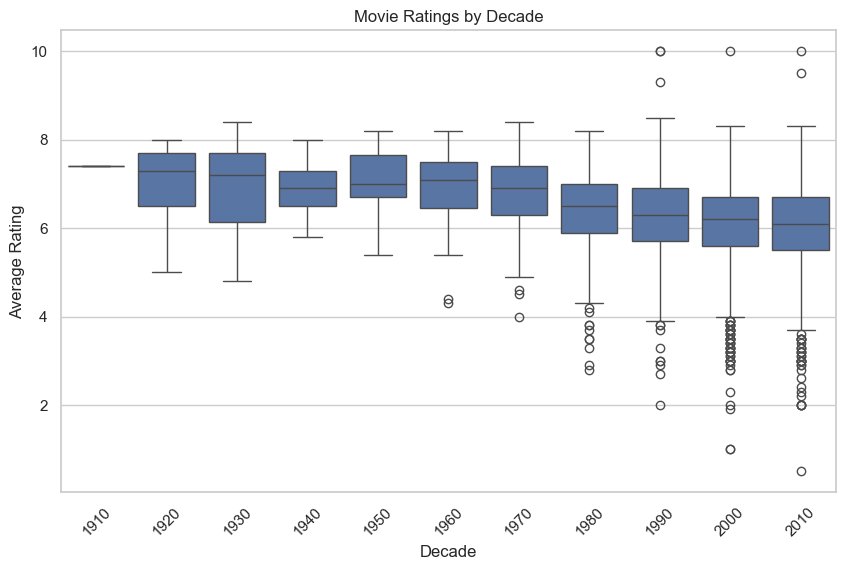

In [24]:
# Step 3.4.2: Boxplot of ratings across decades
plt.figure(figsize=(10, 6))
sns.boxplot(x='decade', y='vote_average', data=df)
plt.title('Movie Ratings by Decade')
plt.xlabel('Decade')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.show()

This boxplot compares average ratings across different decades.

- The median rating has remained relatively stable over time.
- There may be slightly more variation in some decades.
- Some decades (e.g., earlier ones) have fewer movies, which may affect the reliability of those statistics.

Temporal analysis helps identify trends or biases in how movies are rated over time.


#### 3.4.3 Relationship Between Runtime and Rating



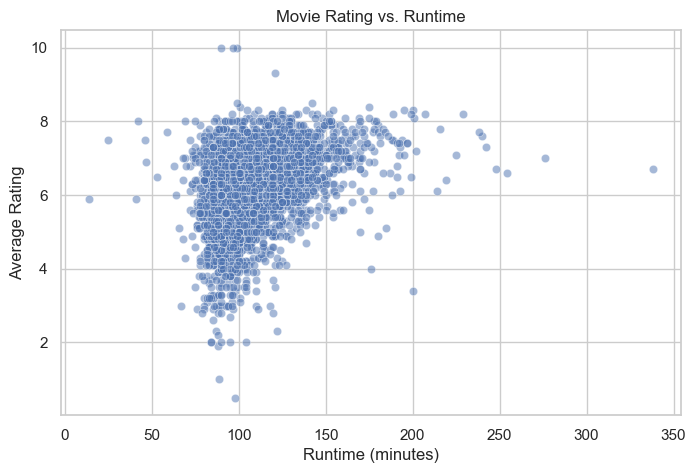

In [25]:
# Step 3.4.3: Scatter plot of rating vs runtime
plt.figure(figsize=(8, 5))
sns.scatterplot(x='runtime', y='vote_average', data=df, alpha=0.5)
plt.title('Movie Rating vs. Runtime')
plt.xlabel('Runtime (minutes)')
plt.ylabel('Average Rating')
plt.show()


The scatter plot suggests a weak positive relationship between runtime and rating — longer movies may receive slightly higher ratings.

However, the effect is not strong, and there are high-rated movies at all runtime lengths. Runtime alone is not a sufficient indicator of quality.


### 3.4 Genre Extraction and Analysis

> **Top 10 Most Common Genres!**

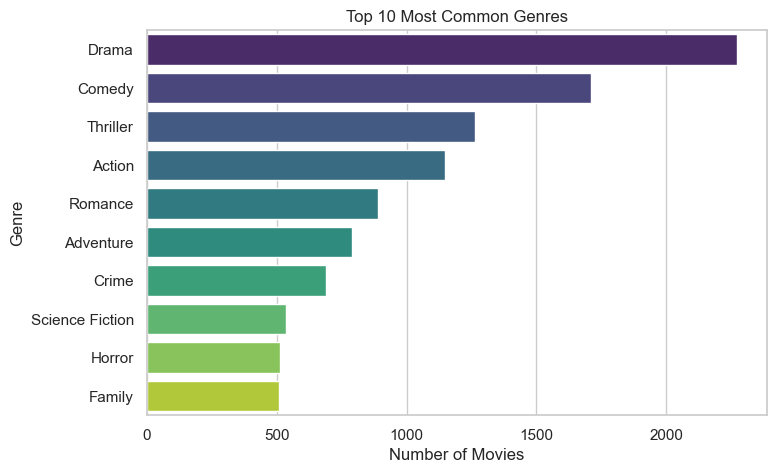

In [26]:
# Step 3.4: Extract and Analyze Genres
import ast
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.preprocessing import MultiLabelBinarizer


# Extract genres
def extract_genre_names(genre_str):
    try:
        genres = ast.literal_eval(genre_str)
        return [g['name'] for g in genres]
    except:
        return []

df['genre_list'] = df['genres'].apply(extract_genre_names)

# Count frequency
all_genres = sum(df['genre_list'], [])
genre_counts = Counter(all_genres)
top_genres = genre_counts.most_common(10)
genre_df = pd.DataFrame(top_genres, columns=['Genre', 'Count'])

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=genre_df, x='Count', y='Genre', hue='Genre', palette='viridis', legend=False)
plt.title('Top 10 Most Common Genres')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.show()

The `genres` field contains string representations of lists of dictionaries. I used `ast.literal_eval()` to safely parse each string and extract the genre names.

- Created a new column `genre_list` containing a list of genres per movie.
- Calculated the frequency of each genre across all movies.
- Bar plot shows the 10 most common genres, with 'Drama', 'Comedy', and 'Action' among the top.


### 3.5 Keyword Analysis via WordCloud

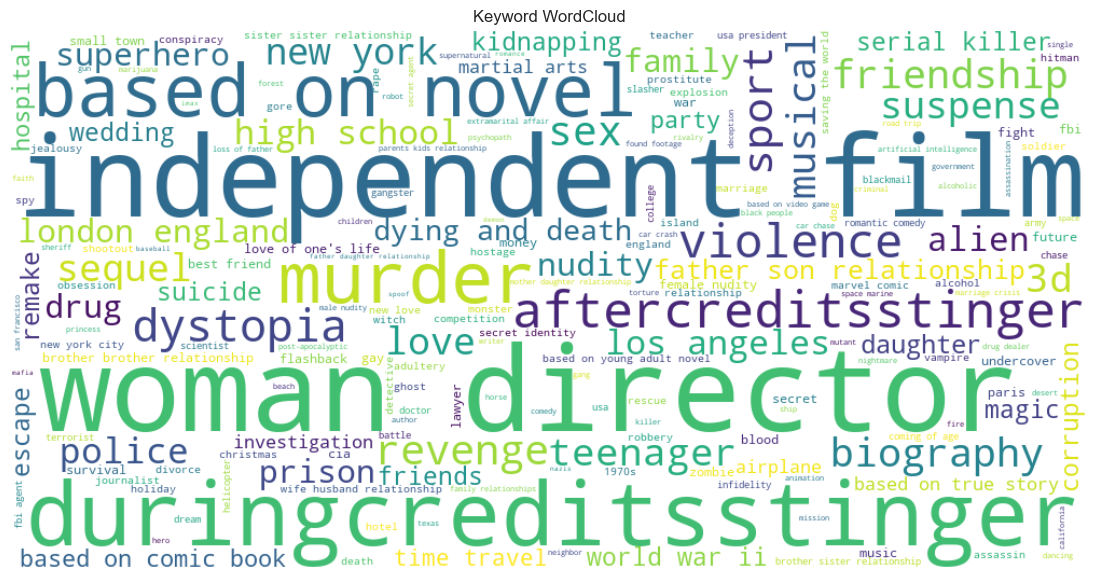

In [27]:
# Step 3.5: Extract Keywords and Generate Word Cloud
def extract_keywords(k_str):
    try:
        kws = ast.literal_eval(k_str)
        return [k['name'] for k in kws]
    except:
        return []

df['keyword_list'] = df['keywords'].apply(extract_keywords)

all_keywords = sum(df['keyword_list'], [])
keywords_freq = Counter(all_keywords)

wordcloud = WordCloud(width=1000, height=500, background_color='white').generate_from_frequencies(keywords_freq)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Keyword WordCloud')
plt.show()


The `keywords` field was parsed to extract keyword terms.

- Created `keyword_list` for each movie.
- Built a frequency dictionary and visualized common keywords using a word cloud.

The keyword word cloud reveals the most frequently occurring narrative themes in the dataset, such as 'love', 'friendship', and 'violence', offering intuitive insight into recurring storytelling motifs.


### 3.6 Production Countries Analysis

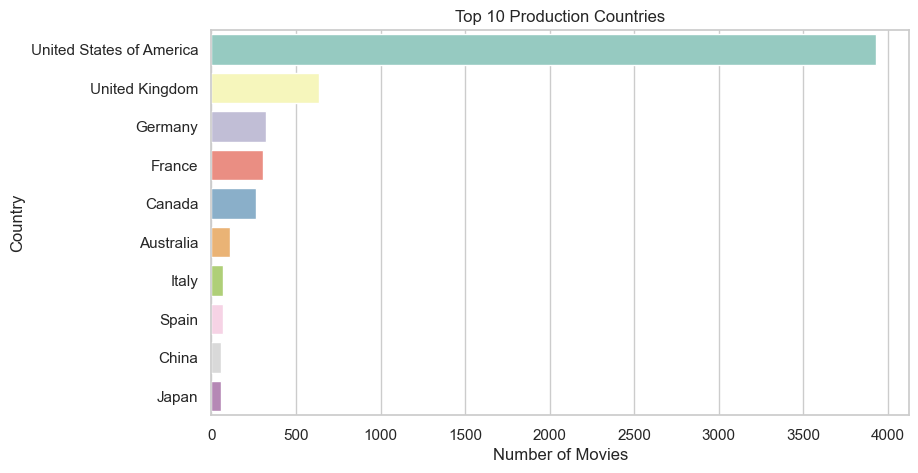

In [28]:
# Step 3.6: Extract Production Countries
def extract_countries(c_str):
    try:
        countries = ast.literal_eval(c_str)
        return [c['name'] for c in countries]
    except:
        return []

df['country_list'] = df['production_countries'].apply(extract_countries)

all_countries = sum(df['country_list'], [])
country_counts = Counter(all_countries)
top_countries = country_counts.most_common(10)
country_df = pd.DataFrame(top_countries, columns=['Country', 'Count'])

plt.figure(figsize=(9, 5))
sns.barplot(data=country_df, x='Count', y='Country', hue='Country', palette='Set3', legend=False)
plt.title('Top 10 Production Countries')
plt.xlabel('Number of Movies')
plt.ylabel('Country')
plt.show()


Parsed the `production_countries` field to extract country names.

- United States is the top production country by far.
- Geographic distribution helps identify global film production patterns.

### 3.7 Spoken Languages Analysis

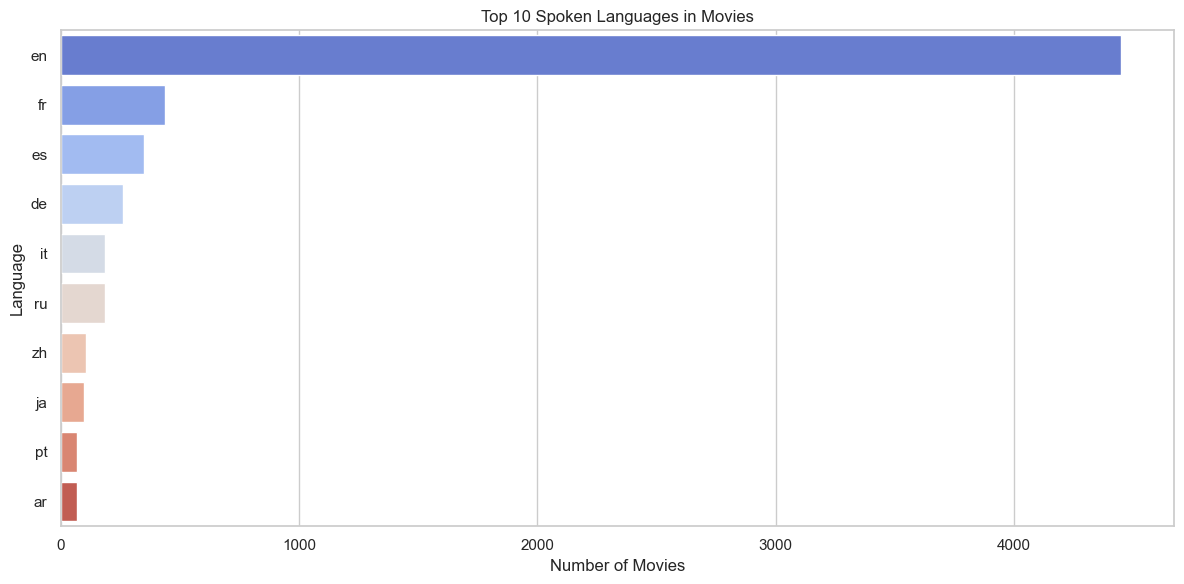

In [29]:
# Step 3.7: Extract Spoken Languages
def extract_languages(l_str):
    try:
        langs = ast.literal_eval(l_str)
        return [l['iso_639_1'] for l in langs]
    except:
        return []

df['language_list'] = df['spoken_languages'].apply(extract_languages)

all_languages = sum(df['language_list'], [])
language_counts = Counter(all_languages)
top_languages = language_counts.most_common(10)
lang_df = pd.DataFrame(top_languages, columns=['Language', 'Count'])

plt.figure(figsize=(12, 6))
sns.barplot(data=lang_df, x='Count', y='Language', hue='Language', palette='coolwarm', legend=False)
plt.title('Top 10 Spoken Languages in Movies')
plt.xlabel('Number of Movies')
plt.ylabel('Language')
plt.tight_layout()  
plt.show()

Parsed the `spoken_languages` field to get language names.

- English is the dominant language, followed by French and Spanish.
- Helps identify audience reach and cultural representation.


In [30]:
#  Rating by Country and Language
df_country_rating = df.explode('country_list').groupby('country_list')['vote_average'].mean().sort_values(ascending=False).head(10)
df_lang_rating = df.explode('language_list').groupby('language_list')['vote_average'].mean().sort_values(ascending=False).head(10)

print("Top 10 Countries by Average Rating:")
print(df_country_rating)

print("\nTop 10 Languages by Average Rating:")
print(df_lang_rating)


Top 10 Countries by Average Rating:
country_list
Egypt                     7.800000
Libyan Arab Jamahiriya    7.400000
Iran                      7.375000
Indonesia                 7.300000
Cameroon                  7.300000
Monaco                    7.300000
Austria                   7.083333
Dominica                  7.000000
Taiwan                    7.000000
Argentina                 6.988889
Name: vote_average, dtype: float64

Top 10 Languages by Average Rating:
language_list
ne    7.700000
xx    7.550000
te    7.500000
id    7.400000
ml    7.400000
km    7.350000
st    7.300000
ny    7.300000
fa    7.225000
ga    7.216667
Name: vote_average, dtype: float64


## Step 4: Data Mining and Modelling


### 4.1 Correlation Analysis

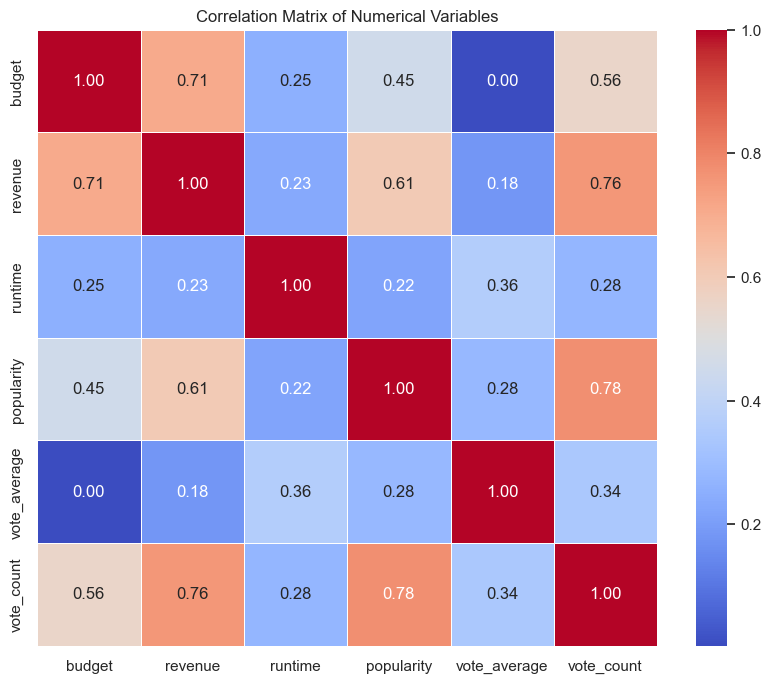

In [31]:
# Step 4.1: Correlation heatmap for numerical features
plt.figure(figsize=(10, 8))
numerical_cols = ['budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count']
corr_matrix = df[numerical_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Variables')
plt.show()


I computed and visualised the Pearson correlation coefficients between key numerical variables.

- `vote_average` (rating) has only weak correlation with most other variables.
- `budget`, `revenue`, and `vote_count` show moderate positive correlation with each other, which is expected as they relate to movie scale and popularity.
- `popularity` correlates more with `vote_count` than with `vote_average`, indicating it may reflect visibility rather than quality.

This correlation analysis helps identify which variables are potentially useful for clustering or classification.

### 4.2 KMeans Clustering


In this step, I used **unsupervised learning (KMeans clustering)** to segment movies into distinct groups based on their key numeric characteristics.

The goal is to identify potential clusters or profiles of movies based on popularity, rating, and other measurable traits — without using any label like "high-rated".


In [32]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

cluster_features = ['vote_average', 'vote_count', 'popularity', 'runtime']
df_cluster = df[cluster_features].dropna().copy()
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_cluster)

silhouette_scores = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k}, silhouette score={score:.3f}")

  File "C:\Users\86137\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\86137\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\86137\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\86137\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


k=2, silhouette score=0.503


k=3, silhouette score=0.292


k=4, silhouette score=0.298


k=5, silhouette score=0.280


k=6, silhouette score=0.290


k=7, silhouette score=0.274


k=8, silhouette score=0.262


k=9, silhouette score=0.267


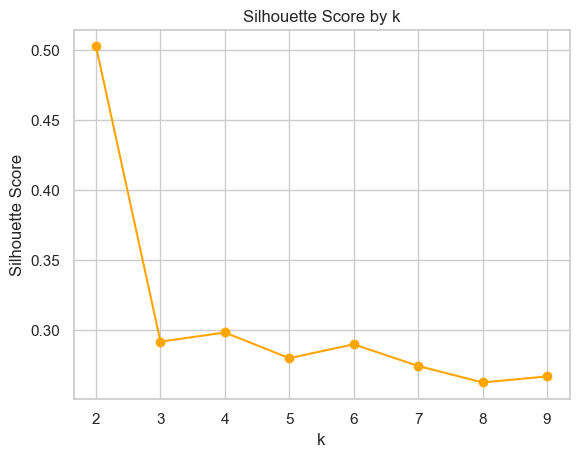

In [33]:
# Plot silhouette scores (computed in the previous cell)
plt.plot(range(2, 10), silhouette_scores, marker='o', color='orange')
plt.title('Silhouette Score by k')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.show()

To choose the number of clusters, I compared silhouette scores for k = 2 to 10. The highest score was k = 2 (0.503), so I use two clusters. Silhouette score tends to favour smaller k, so this is best read as a coarse "high-visibility vs. low-visibility" split rather than proof that the data naturally contains exactly two groups.

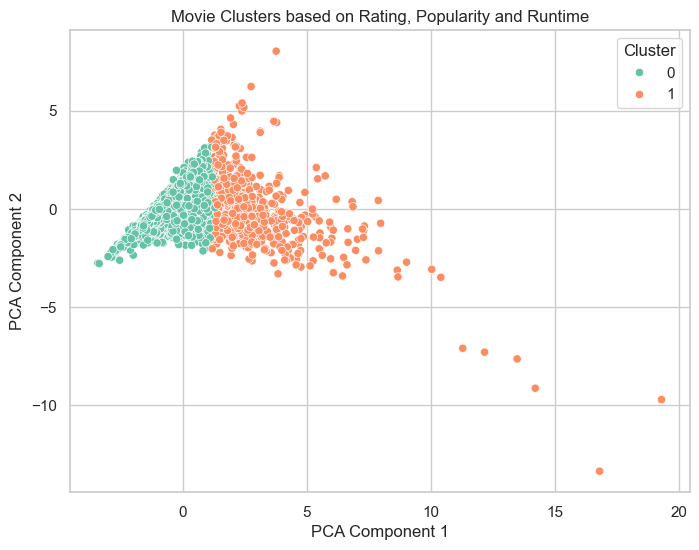

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Step 4.2.1: Select features and drop missing
cluster_features = ['vote_average', 'vote_count', 'popularity', 'runtime']
df_cluster = df[cluster_features].dropna().copy()

# Step 4.2.2: Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

# Step 4.2.3: Apply KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
df_cluster['cluster'] = kmeans.fit_predict(X_scaled)

# Step 4.2.4: PCA for visualisation
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
df_cluster['pca1'] = components[:, 0]
df_cluster['pca2'] = components[:, 1]

# Step 4.2.5: Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_cluster, x='pca1', y='pca2', hue='cluster', palette='Set2')
plt.title('Movie Clusters based on Rating, Popularity and Runtime')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.show()



In [35]:
profile = (
    df_cluster
    .groupby('cluster')[['vote_average', 'vote_count', 'popularity', 'runtime']]
    .agg(['mean', 'median', 'min', 'max'])
    .round(2)
)
profile


vote_average                   vote_count                         \
                mean median  min   max       mean  median   min      max   
cluster                                                                    
0               6.04    6.1  0.5  10.0     344.32   179.0   1.0   3462.0   
1               7.06    7.1  4.9   8.5    2953.63  2458.5  12.0  13752.0   

        popularity                      runtime                      
              mean median   min     max    mean median   min    max  
cluster                                                              
0            14.42  10.81  0.00   76.84  104.10  101.0  14.0  200.0  
1            68.73  58.53  1.14  875.58  131.08  126.0  81.0  338.0

#### Cluster Interpretation (k = 2, based on profile statistics)

Using the chosen value of k = 2 (based on highest silhouette score of 0.503), I analyzed the characteristics of each cluster using group-level statistics:

**Cluster 0 — Smaller-scale or Low-profile Movies**
- Lower average rating (**6.04**), with fewer votes (**344**) and significantly lower popularity scores (**14.42**)
- Shorter runtime on average (**104 mins**), likely indicating more independent, niche, or less successful films
- Maximum values are also capped at relatively modest levels (e.g., max votes: 3462)

**Cluster 1 — Blockbusters or Critically Acclaimed Films**
- Higher average rating (**7.06**), significantly more votes (**~2954**) and much higher popularity (**~68.7**)
- Longer runtime (**131 mins** on average), consistent with more mainstream or ambitious productions
- Higher max values indicate inclusion of large-scale or high-budget movies (e.g., vote_count up to 13,752)

**Conclusion**:  
The two clusters clearly separate movies by overall visibility and success. Cluster 1 contains movies that are both **more popular and better rated**, while Cluster 0 contains **less visible or lower-performing titles**.

This segmentation could be useful for downstream applications like recommendation engines or marketing strategy.



### 4.3 Factors Associated with High-Rated Movies



This section examines which measurable attributes are associated with a **high rating**. Note that `budget`, `revenue`, `runtime`, and `popularity` are mostly known only after release, so this is an association analysis rather than a pre-release prediction.

Originally, I defined a high-rated movie as one with `vote_average ≥ 8.0`, but this led to a severe class imbalance: only ~30 movies in the dataset were classified as high-rated. The classification model failed to identify most of them, with recall only 13%.

To improve this, I adjusted the threshold to `vote_average ≥ 7.0`, a more inclusive yet still reasonable definition of a well-rated movie. This change increased the number of positive examples to 292, making the classification task more balanced and the evaluation more meaningful.

              precision    recall  f1-score   support

       False       0.98      1.00      0.99      1392
        True       0.67      0.13      0.22        30

    accuracy                           0.98      1422
   macro avg       0.82      0.57      0.61      1422
weighted avg       0.97      0.98      0.97      1422

Majority-class baseline accuracy: 0.979


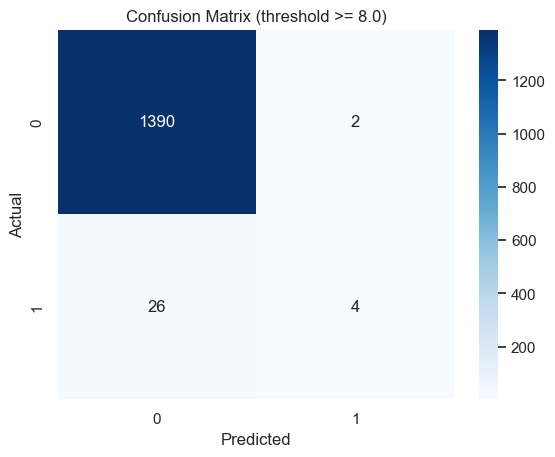

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Step 4.3: high-rating label at the strict 8.0 threshold (severe class imbalance)
features = ['budget', 'revenue', 'runtime', 'popularity']
X = df[features].fillna(0)
y = df['is_high_rating1']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

# Majority-class baseline: accuracy of always predicting the most common class
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline accuracy: {baseline:.3f}")
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (threshold >= 8.0)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


The Decision Tree classifier reports 98% accuracy, but this is no better than the majority-class baseline shown above (always predicting "not high-rated" also gives ~98%), revealing a severe class imbalance:

- Only 30 movies in the test set were labeled as high-rated (`is_high_rating=True`), compared to 1392 non-high-rated.
- While precision for the positive class is 0.67, the **recall is only 0.13**, meaning most high-rated movies were not detected.
- The model tends to classify all movies as "not high-rated" to achieve high accuracy.

This highlights the **class imbalance problem**, where the minority class is underrepresented and the model fails to learn its characteristics.




              precision    recall  f1-score   support

       False       0.85      0.95      0.90      1130
        True       0.66      0.35      0.45       292

    accuracy                           0.83      1422
   macro avg       0.76      0.65      0.68      1422
weighted avg       0.81      0.83      0.81      1422

Majority-class baseline accuracy: 0.795


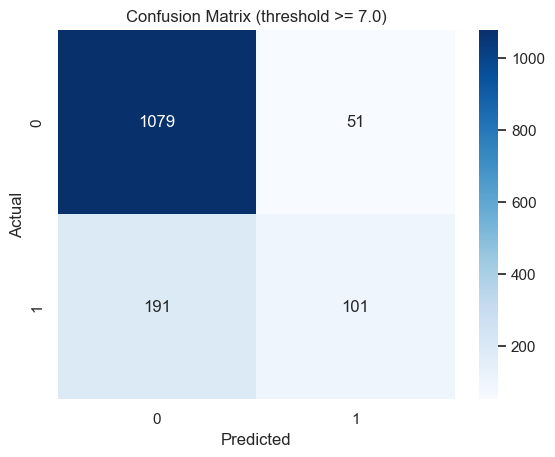

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Step 4.3: high-rating label at the more inclusive 7.0 threshold
features = ['budget', 'revenue', 'runtime', 'popularity']
X = df[features].fillna(0)
y = df['is_high_rating2']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

# Majority-class baseline for comparison
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline accuracy: {baseline:.3f}")
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (threshold >= 7.0)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

With the more inclusive threshold (>= 7.0), the positive class grows from 30 to 292 examples, so the model can learn the "high-rated" profile instead of almost always predicting the majority class.

Classification summary (test set)

| Threshold | Positive count | Accuracy | Majority-class baseline | Recall (positive) | F1 (positive) |
|-----------|----------------|----------|--------------------------|-------------------|---------------|
| >= 8.0 | 30 | 0.98 | 0.98 | 0.13 | 0.22 |
| >= 7.0 | 292 | 0.83 | 0.80 | 0.35 | 0.45 |

The 7.0 threshold gives a more balanced task: the model beats its baseline (0.83 vs 0.80) and detects far more high-rated films, though recall remains modest (0.35).

Note: even at the 7.0 threshold the positive class is still a minority, so the model remains somewhat biased toward predicting the majority class.

#### Going further: discrimination, imbalance, and robustness

Three follow-ups make the picture clearer: ROC-AUC measures how well the model ranks high-rated films regardless of the classification threshold; balanced class weights tackle the imbalance directly; and cross-validation checks that the result is stable rather than a lucky train/test split.

In [38]:
from sklearn.metrics import roc_auc_score

# AUC measures ranking quality independent of the 0.5 classification threshold
# (clf is the 7.0-threshold decision tree fitted above)
auc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
print(f"ROC-AUC (>= 7.0 model): {auc:.3f}")

ROC-AUC (>= 7.0 model): 0.785


In [39]:
# Tackle the imbalance directly by weighting the minority class more heavily
clf_bal = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
clf_bal.fit(X_train, y_train)
y_pred_bal = clf_bal.predict(X_test)

print(classification_report(y_test, y_pred_bal))

              precision    recall  f1-score   support

       False       0.90      0.75      0.82      1130
        True       0.41      0.70      0.52       292

    accuracy                           0.74      1422
   macro avg       0.66      0.72      0.67      1422
weighted avg       0.80      0.74      0.76      1422



In [40]:
from sklearn.model_selection import cross_val_score

# A single split can be lucky; 5-fold CV gives a stable estimate
cv_acc = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42), X, y, cv=5, scoring='accuracy')
cv_auc = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42), X, y, cv=5, scoring='roc_auc')
print(f"5-fold CV accuracy: {cv_acc.mean():.3f} +/- {cv_acc.std():.3f}")
print(f"5-fold CV ROC-AUC:   {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")

5-fold CV accuracy: 0.798 +/- 0.019
5-fold CV ROC-AUC:   0.702 +/- 0.054


#### What the follow-ups show

- **Discrimination (ROC-AUC).** The 7.0-threshold model reaches a single-split ROC-AUC of **0.785**; 5-fold cross-validation gives a more conservative **0.702 +/- 0.054**. Both are clearly above the 0.5 random baseline, so the model captures real signal - but the gap between 0.785 and 0.702 shows why a single split should not be trusted on its own.
- **Imbalance (balanced class weights).** Weighting the minority class lifts recall on high-rated films from **0.35 to 0.70** - the model now finds most high-rated films. The cost is the usual precision-recall trade-off: precision drops from 0.66 to 0.41 (more false positives) and accuracy falls from 0.83 to 0.74, while F1 improves from 0.45 to 0.52.
- **Stability (cross-validation).** Accuracy is stable at **0.798 +/- 0.019** across folds, so the earlier results are not a lucky split.

**Takeaway.** The feature importances explain why the signal is limited: the model leans almost entirely on `popularity` (0.463), with `runtime` (0.282) and `budget` (0.248) secondary, and `revenue` essentially ignored (0.006). Because `popularity` is a post-release, partly vote-driven metric, "high popularity implies high rating" is close to circular - and that is itself the finding: the pre-release levers people usually imagine (such as budget) are weak predictors of whether a film will be well received.

revenue       0.006
budget        0.248
runtime       0.282
popularity    0.463
dtype: float64


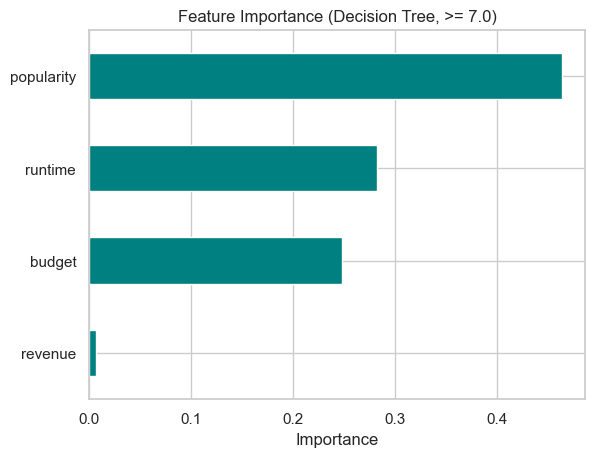

In [41]:
# Feature importance of the final model (7.0 threshold)
importances = pd.Series(clf.feature_importances_, index=features).sort_values()
print(importances.round(3))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance (Decision Tree, >= 7.0)')
plt.xlabel('Importance')
plt.show()

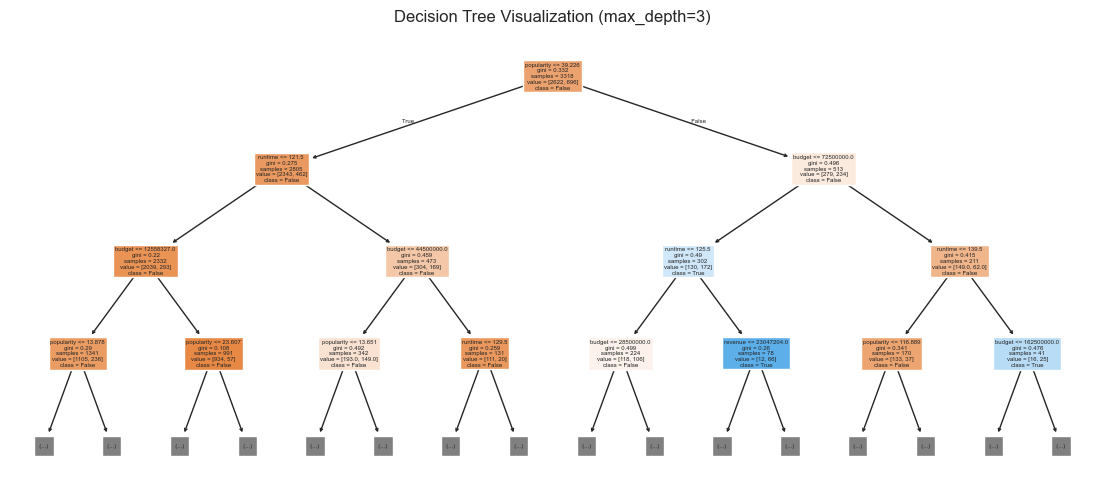

In [42]:
from sklearn import tree

plt.figure(figsize=(14, 6))
tree.plot_tree(clf, feature_names=features, class_names=['False', 'True'],
               filled=True, max_depth=3)
plt.title("Decision Tree Visualization (max_depth=3)")
plt.show()


### 4.4 Step 4 Summary

In this section, I applied correlation analysis, clustering, and classification techniques:

- Correlation heatmaps helped identify related numerical features.
- KMeans clustering revealed a coarse high-visibility vs. low-visibility split in the movie data.
- A decision tree classifier identified which post-release numerical attributes are most associated with a high rating.

These insights provide a deeper understanding of the dataset structure and support potential downstream applications such as recommendation systems or performance forecasting.


# Step 5: Performance and Success Factors

### 5.1: Keyword Analysis — High vs. Low Rated Movies

To investigate thematic differences between high-rated and low-rated movies, I analyzed their most frequent keywords.

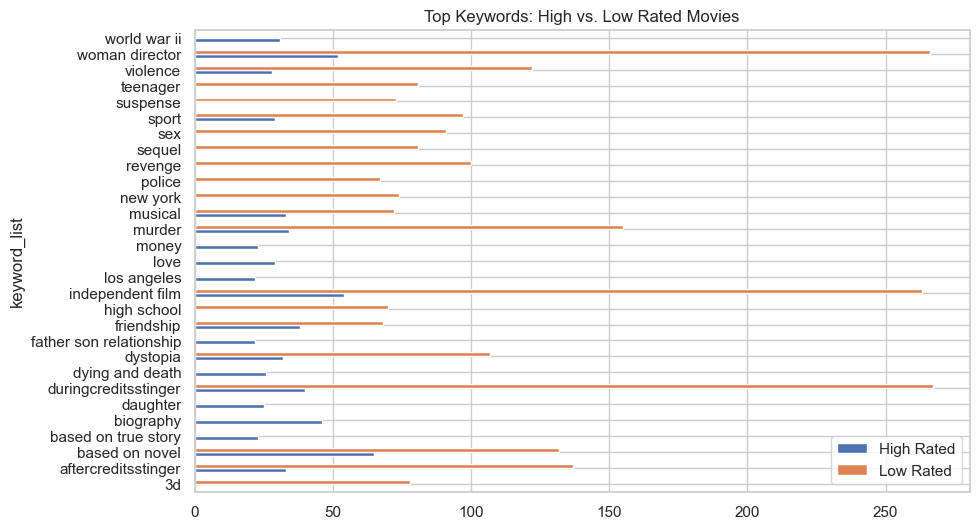

In [43]:
high_keywords = df[df['is_high_rating2']]['keyword_list'].explode().value_counts().head(20)

# Comparision
low_keywords = df[~df['is_high_rating2']]['keyword_list'].explode().value_counts().head(20)

pd.DataFrame({'High Rated': high_keywords, 'Low Rated': low_keywords}).plot(kind='barh', figsize=(10, 6))
plt.title('Top Keywords: High vs. Low Rated Movies')
plt.show()


High-Rated Movie Keywords
High-rated movies tend to include emotionally resonant or realistic themes:
- `"world war ii"`, `"biography"`, `"based on true story"` indicate a preference for history and realism.
- `"love"`, `"friendship"`, and `"father son relationship"` show a leaning toward human emotion and family bonds.
- `"woman director"` also appears, suggesting diversity may be positively correlated with quality perception.

Low-Rated Movie Keywords
In contrast, low-rated movies frequently include:
- Action-oriented or generic terms such as `"violence"`, `"zombie"`, `"revenge"`, `"sequel"`, `"murder"`.
- Technical or franchise-related tags like `"3d"`, `"aftercreditsstinger"` and `"high school"`.

This suggests that while special effects and action elements may be popular, they do not necessarily lead to high audience ratings. Emotional, meaningful storytelling appears to have a stronger impact on overall movie quality.

---

This NLP-based keyword analysis provides a rich layer of **semantic insight** into what types of stories audiences value more highly.


### 5.2 Relationship between Rating and Revenue

The question we want to explore is: 

>Does a "reputation-based movie" equal "commercial success"? 

This can not only help us understand the relationship between ratings and box office, but also unearth some typical groups of "critically acclaimed but not commercially successful" or "commercially successful but not critically acclaimed".

In [44]:
df_revenue = df[(df['revenue'] > 0) & (df['vote_average'] > 0)].copy()


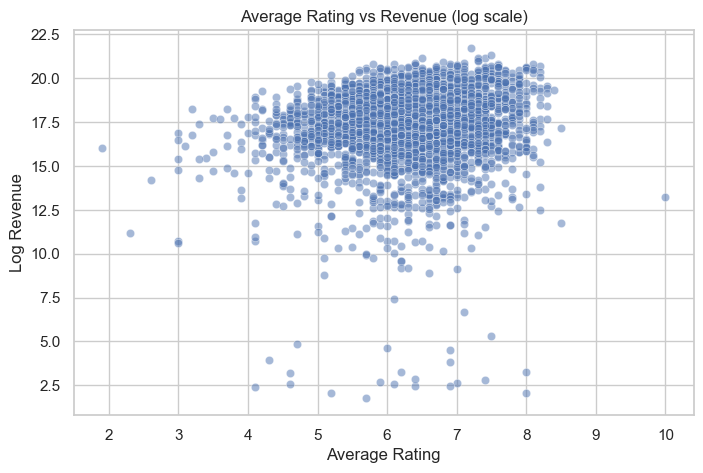

In [45]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_revenue, x='vote_average', y=np.log1p(df_revenue['revenue']), alpha=0.5)
plt.title('Average Rating vs Revenue (log scale)')
plt.xlabel('Average Rating')
plt.ylabel('Log Revenue')
plt.show()


Note: The revenue variable is highly skewed, so I applied a log transform (`log_revenue = log(1 + revenue)`) to improve the visualization and reveal underlying trends.


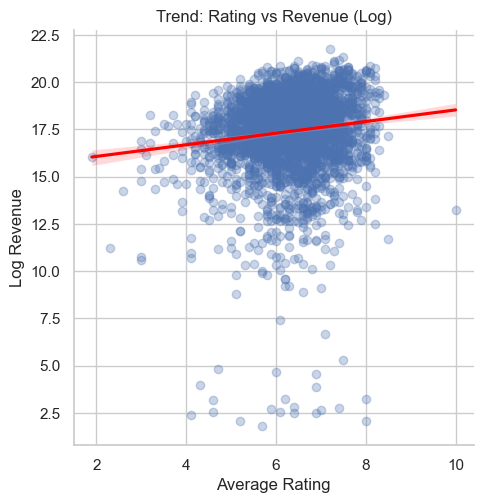

In [46]:
df_revenue['log_revenue'] = np.log1p(df_revenue['revenue'])
sns.lmplot(data=df_revenue, x='vote_average', y='log_revenue',
           scatter_kws={'alpha':0.3}, line_kws={'color':'red'})

plt.title('Trend: Rating vs Revenue (Log)')
plt.xlabel('Average Rating')
plt.ylabel('Log Revenue')
plt.show()



In [47]:
# Define "success" as both well-rated (>= 7.0) and commercially strong (revenue above the median).
# The thresholds are a working definition, not an industry standard.
revenue_median = df['revenue'].median()
df['is_successful'] = (df['vote_average'] >= 7) & (df['revenue'] >= revenue_median)
df['is_successful'].value_counts(normalize=True)


is_successful
False    0.907173
True     0.092827
Name: proportion, dtype: float64

Using the combined criteria of `vote_average ≥ 7` and `revenue ≥ median`, I labeled each movie as either:

- **Successful** (both critically and commercially)
- **Not successful** (missing one or both targets)

Result:
- Only **9.3%** of the movies achieved dual success.  
- The remaining **90.7%** either did not perform well in terms of audience ratings or did not generate above-median revenue.

Insight:
- Achieving both **artistic merit and commercial success** is clearly rare.
- This highlights the competitive and unpredictable nature of the film industry.
- The `is_successful` feature can now be used for further analysis, such as identifying which **genres**, **keywords**, or **countries** tend to produce more successful movies.


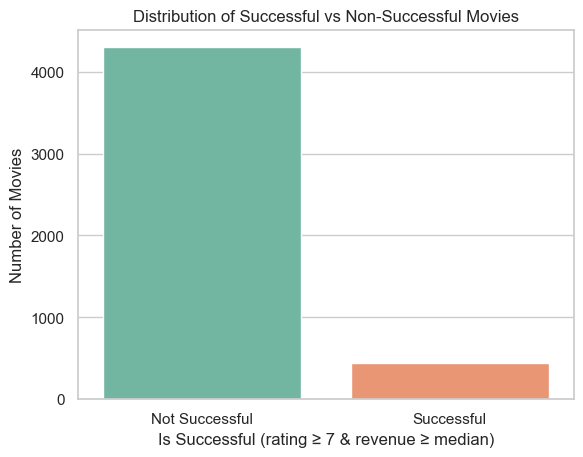

In [48]:
sns.countplot(x='is_successful', data=df, hue='is_successful', palette='Set2', legend=False)
plt.title('Distribution of Successful vs Non-Successful Movies')
plt.xlabel('Is Successful (rating ≥ 7 & revenue ≥ median)')
plt.ylabel('Number of Movies')
plt.xticks([0, 1], ['Not Successful', 'Successful'])
plt.show()


### 5.3 Analyze success rate and score distribution by genre

> Which types of movies are more likely to get high ratings?

#### 5.3.1: Rating Distribution by Genre

In [49]:
df['genre_list'].head()


0    [Action, Adventure, Fantasy, Science Fiction]
1                     [Adventure, Fantasy, Action]
2                       [Action, Adventure, Crime]
3                 [Action, Crime, Drama, Thriller]
4             [Action, Adventure, Science Fiction]
Name: genre_list, dtype: object



To examine how audience ratings differ across genres, I used a boxplot to visualize the distribution of vote_average for each genre. This reveals which genres are consistently rated higher and which have broader variability.


In [50]:
df['genre_list'] = df['genre_list'].apply(lambda x: x if isinstance(x, list) else [])

from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
genre_dummies = mlb.fit_transform(df['genre_list']) 
genre_df = pd.DataFrame(genre_dummies, columns=mlb.classes_)

df = pd.concat([df, genre_df], axis=1)


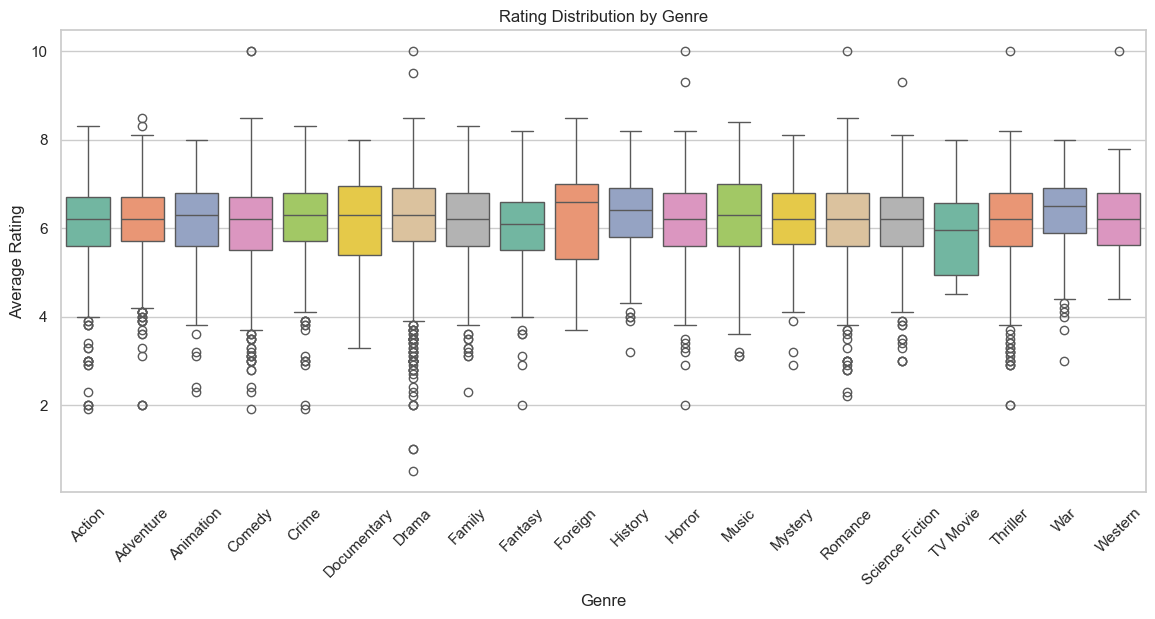

In [51]:

df_genres = df.melt(id_vars=['vote_average'], 
                    value_vars=mlb.classes_, 
                    var_name='Genre', 
                    value_name='Is_Genre')
df_genres = df_genres[df_genres['Is_Genre'] == 1]
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_genres, x='Genre', y='vote_average', hue='Genre', palette='Set2', legend=False)
plt.xticks(rotation=45)
plt.title('Rating Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Rating')
plt.show()



Genres like Documentary, Foreign, History, and Music tend to have higher median ratings, reflecting strong audience appreciation. Meanwhile, Action, Documentary, Drama and Horror films exhibit broader rating distributions, suggesting mixed reception. This highlights how genre influences audience perception.


#### 5.3.2: Success Rate by Genre


To identify which genres are more likely to produce both critically and commercially successful movies (rating ≥ 7 and above-median revenue), I calculated the success rate within each genre.


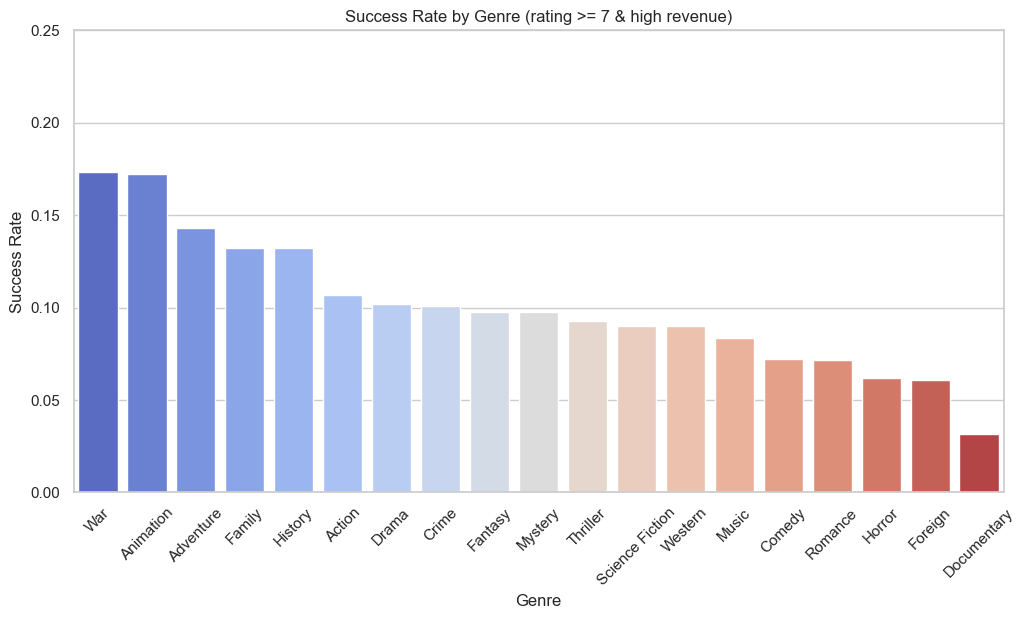

In [52]:
genre_success = {}

# Only include genres with enough movies so success rates are not driven by tiny samples
MIN_MOVIES = 20

for genre in mlb.classes_:
    subset = df[df[genre] == 1]
    if len(subset) < MIN_MOVIES:
        continue
    genre_success[genre] = subset['is_successful'].mean()


genre_success_df = pd.DataFrame.from_dict(genre_success, orient='index', columns=['Success Rate'])
genre_success_df = genre_success_df.sort_values('Success Rate', ascending=False)


plt.figure(figsize=(12, 6))
sns.barplot(x=genre_success_df.index, y='Success Rate', data=genre_success_df, hue=genre_success_df.index, palette='coolwarm', legend=False)
plt.xticks(rotation=45)
plt.title('Success Rate by Genre (rating >= 7 & high revenue)')
plt.xlabel('Genre')
plt.ylabel('Success Rate')
plt.ylim(0, 0.25)
plt.show()

Genres such as Animation, and Adventure have the highest success rates, indicating their strong potential for dual success. On the other hand, Horror, Thriller genres show lower success rates. This suggests that lighter, family-friendly, or emotionally engaging genres are more likely to perform well in both audience ratings and revenue.


# Conclusion and Key Takeaways

This project explored a movie dataset from a data mining and visualization perspective, aiming to understand what makes a film successful — both critically and commercially.

**1. Data Cleaning & Feature Engineering**

I began by handling missing values, detecting pseudo-missing values such as zeros in budget/revenue fields, and transforming key variables like release date, genres, and keywords into usable formats. I created derived features such as decade, binary high-rating labels, and extracted genre lists. This careful preparation laid a solid foundation for meaningful analysis.

**2. Exploratory Data Analysis (EDA)**

Through scatter plots, distributions, and trend lines, I examined relationships such as:
- Budget vs. rating (weak correlation)
- Rating vs. revenue (moderate correlation, high variance)
- Keyword and genre differences between high- and low-rated films

These visuals helped uncover both expected and surprising insights, such as the fact that certain emotionally resonant themes (e.g., “friendship”, “biography”) dominate in well-rated movies, while overly generic or violent keywords are more common in poorly rated ones.

**3. Clustering and Audience Perception**

I applied KMeans clustering (k=2) based on features like vote_average, vote_count, popularity, and runtime. The resulting clusters captured a clear divide between highly popular and high-rated “blockbusters” and low-budget, low-rating films. This unsupervised analysis provided another lens to segment the movie landscape without using explicit labels.

**4. Genre-Based Analysis**

One of the most insightful parts was the genre analysis:
- Boxplots showed that genres like Documentary and Music tend to receive higher ratings, while Horror and Action are more volatile.
- A separate analysis revealed that genres such as Animation and Adventure have higher proportions of “successful” movies (rating ≥ 7 and above-median revenue).

This genre-level understanding is valuable for both marketing strategy and production planning, highlighting how content style affects reception.

**5. Reflection**

Rather than simply visualizing data, I focused on asking analytical questions:
- What patterns separate high-rated movies from low-rated ones?
- Are budget and revenue predictive of audience reception?
- Which genres consistently perform well?

This inquiry-driven approach helped turn raw data into strategic insights. While additional modeling steps (e.g., profit analysis or prediction models) were left for future work, this notebook already reveals rich multidimensional relationships across rating, genre, and revenue.

